## Pregunta 2

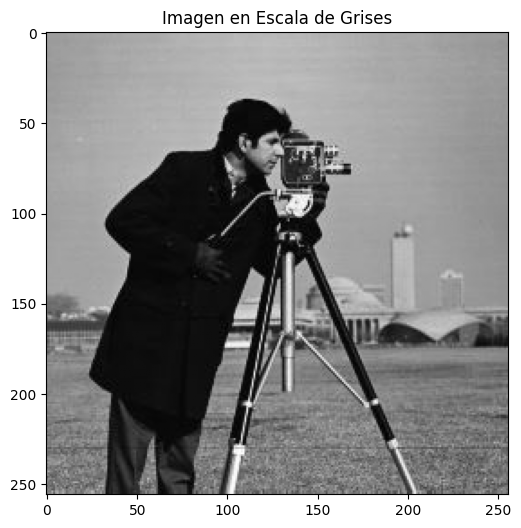

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
ruta_imagen = 'cameraman.jpg' 
img = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.title('Imagen en Escala de Grises')
plt.show()

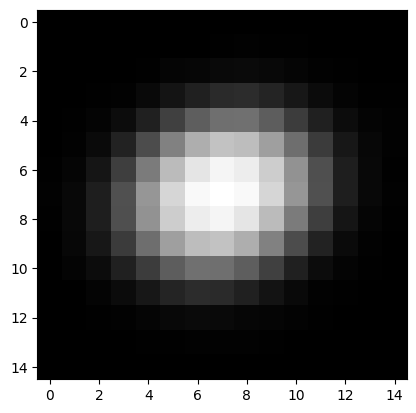

In [ ]:
# Cargar la PSF
h = cv2.imread('psf.png', cv2.IMREAD_GRAYSCALE)

#normalizar
h = h.astype(np.float32)
h = h / np.sum(h)
plt.imshow(h, cmap='gray')
plt.show()

Comienzo con el filtro de Wiener, pero este necesita H que es la respuesta en frecuencia de la PSF

In [6]:
def construirH(psf, formaImagen):
    #comienzo con la matriz vacia
    psfPad = np.zeros(formaImagen, dtype=np.float32)
    ph, pw = psf.shape
    
    #se coloca la PSF en el centro
    yCentro = formaImagen[0] // 2
    xCentro = formaImagen[1] // 2
    psfPad[yCentro - ph // 2 : yCentro - ph // 2 + ph, 
           xCentro - pw // 2 : xCentro - pw // 2 + pw] = psf
           
    #y se realiza el shifteo
    psfCentrada = np.fft.fftshift(psfPad)
    
    #y entrega la transofrmada que me piden
    return np.fft.fft2(psfCentrada)

aca es pasar la ecuacion que me dan a una funcion


In [9]:
def filtroWiener(y, H, kValor):
    #transformada imagen degradada
    Y = np.fft.fft2(y)
    #H conjugado
    hConj = np.conj(H)
    
    denominador = np.abs(H)**2 + kValor
    Xhat = (hConj * Y) / denominador
    
    return np.abs(np.fft.ifft2(Xhat))

Ahora iré directamente a la parte B, porque también me dan explícitamente las ecuaciones para definir

Se ve que tengo que usar H y Ht para la actualización recomendada, así que es lo primero que defino.

In [11]:
#en la funcion x es la imagen y H es la función de transferencia PSF

def aplicarH(x, H):
    return np.real(np.fft.ifft2(np.fft.fft2(x) * H))

def aplicarHt(x, H):
    return np.real(np.fft.ifft2(np.fft.fft2(x) * np.conj(H)))

In [12]:
def tikhonovGradiente(y, H, xIdeal, lam, tau, maxIter, tol):
    x = np.copy(y)  # Inicialización con la imagen observada
    listaCostos = []
    listaRmse = []
    
    for k in range(maxIter):
        #H*x y residuo
        Hx = aplicarH(x, H)
        residuo = Hx - y
        # H^T(Hx - y) + lambda * x
        grad = aplicarHt(residuo, H) + lam * x
        
        #x^(k+1)
        xNuevo = x - tau * grad
        
        #esto es lo que deseo minimizar
        costo = 0.5 * np.sum(residuo**2) + 0.5 * lam * np.sum(x**2)
        listaCostos.append(costo)
        
        # guardo valores RMSE
        if xIdeal is not None:
            rmse = np.sqrt(np.mean((xNuevo - xIdeal)**2))
            listaRmse.append(rmse)
        
        #wsi el gradiente es prácticamente cero, se detiene
        magnitudGradiente = np.linalg.norm(grad)
        if magnitudGradiente < tol:
            break
        #otra iteracion
        x = xNuevo

    return x, listaCostos, listaRmse

Para la experimentacion y analissi empiezo desde definir mis variables

In [22]:
#PSF y normalizar
h = cv2.imread('psf.png', cv2.IMREAD_GRAYSCALE).astype(np.float32)
h = h / np.sum(h)
H = construirH(h, img.shape)

Acá revisaré dos niveles de ruido 

In [30]:
#defino mi dos ruidos , uno bajo y otro 10 veces mpas altio
ruidoBajo = np.random.normal(0, 0.01, img.shape)
ruidoAlto = np.random.normal(0, 0.1, img.shape)
yBajo = aplicarH(img, H) + ruidoBajo
yAlto = aplicarH(img, H) + ruidoAlto

#defino esto para la escala logaritmica

kValores = np.logspace(-6, 0, 30)

#calculo el RMSE para cada valor de K
rmsesBajo = [np.sqrt(np.mean((filtroWiener(yBajo, H, k) - img)**2)) for k in kValores]
rmsesAlto = [np.sqrt(np.mean((filtroWiener(yAlto, H, k) - img)**2)) for k in kValores]
mejorKBajo = kValores[np.argmin(rmsesBajo)]
mejorKAlto = kValores[np.argmin(rmsesAlto)]
print(mejorKBajo)
print(mejorKAlto)

1e-06
2.8072162039411757e-05


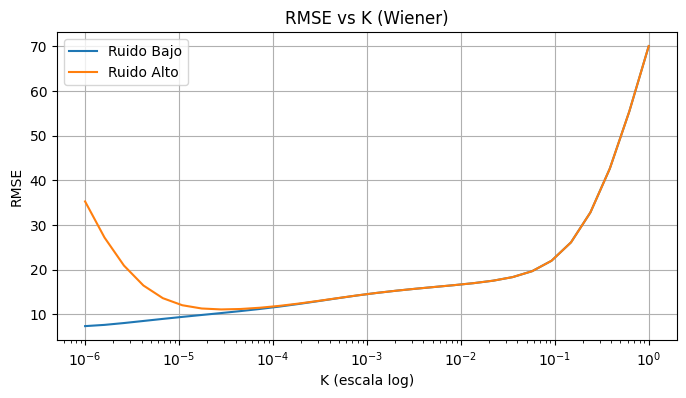

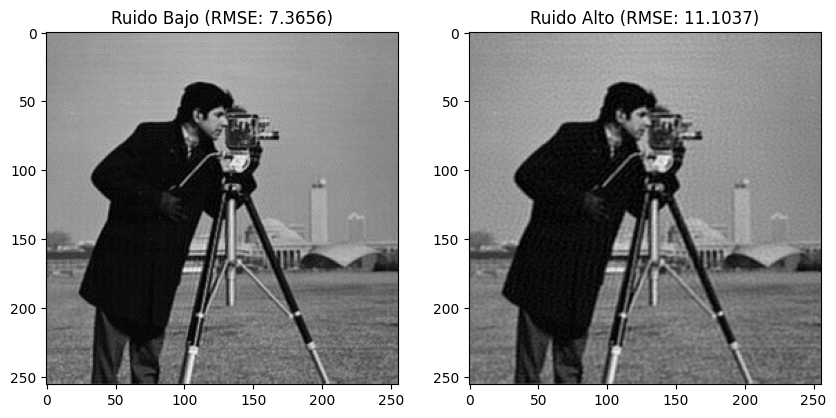

In [38]:
#grafico pedido
plt.figure(figsize=(8, 4))
plt.plot(kValores, rmsesBajo, label=f'Ruido Bajo')
plt.plot(kValores, rmsesAlto, label=f'Ruido Alto')
plt.xscale('log')
plt.xlabel('K (escala log)')
plt.ylabel('RMSE')
plt.title('RMSE vs K (Wiener)')
plt.legend()
plt.grid(True)
plt.show()

#para las imagenes con sus K optimos
imgOptBajo = filtroWiener(yBajo, H, mejorKBajo)
imgOptAlto = filtroWiener(yAlto, H, mejorKAlto)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(imgOptBajo, cmap='gray')
axes[0].set_title(f'Ruido Bajo (RMSE: {min(rmsesBajo):.4f})')
axes[1].imshow(imgOptAlto, cmap='gray')
axes[1].set_title(f'Ruido Alto (RMSE: {min(rmsesAlto):.4f})')
plt.show()

Para definir una PSF ligeramente incorrecta, le aplico un filtro gaussiano

In [21]:
psfMal = cv2.GaussianBlur(h, (5, 5), 2)
psfMal /= np.sum(psfMal)
HMal = construirH(psfMal, img.shape)
imgMal = filtroWiener(yAlto, HMal, mejorKAlto)
rmseMal = np.sqrt(np.mean((imgMal - img)**2))

Y ahora si puedo hacer el análisis

In [ ]:
#comparacion cuantitativa del RMSE
print(min(rmsesAlto))
print(rmseMal)


11.103707062165935
22.348976068569424


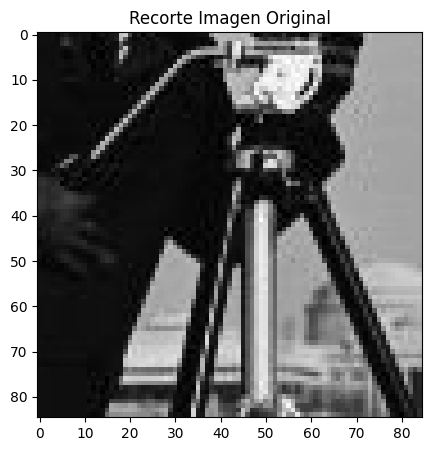

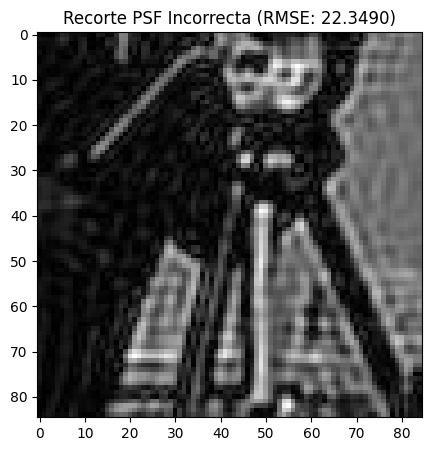

In [45]:
hImg, wImg = img.shape
recorteOrig = img[hImg//3:2*hImg//3, wImg//3:2*wImg//3]
recorteMal = imgMal[hImg//3:2*hImg//3, wImg//3:2*wImg//3]

plt.figure(figsize=(5, 5))
plt.imshow(recorteOrig, cmap='gray')
plt.title('Recorte Imagen Original')
plt.show()

plt.figure(figsize=(5, 5))
plt.imshow(recorteMal, cmap='gray')
plt.title(f'Recorte PSF Incorrecta (RMSE: {rmseMal:.4f})')
plt.show()